# 07 · SoC Vmin prediction

**Goal:** predict each SoC chip's **worst-core minimum voltage (Vmin) at 2 GHz** from the cheap on-chip monitors that
the tester already reads, before any voltage search.

- **Target:** `vmin_worst_mV`, the highest Vmin among the chip's working cores (the core that needs the most voltage
  sets the chip's requirement). Defective cores have no Vmin and are ignored.
- **Inputs:** ring-oscillator frequency, critical-path monitor delay, leakage current (IDDQ), the 5 process monitors and
  the die position: the same monitors as the speed model in notebook 04.
- **Split:** the same wafer split as every other notebook (25% of wafers held out, seed 42). The safety margin is
  chosen on **validation wafers** inside the training wafers, then checked once on the untouched test wafers.

In this synthetic dataset the voltage bin (AVS) is set from each chip's **speed**, not from these Vmin columns, so the
AVS logic of notebook 04 is unchanged. This notebook adds Vmin as its own prediction: a chip's voltage requirement
estimated without a voltage search. All data is synthetic.

In [1]:
import glob, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from scipy.stats import beta
from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
SEED = 42
TEAL, COPPER, GREY = "#0f766e", "#b4501e", "#857a69"


def find(name):
    hits = [h for h in glob.glob(f"**/{name}", recursive=True) if "cleaned" not in h]
    return min(hits, key=len) if hits else None


path = find("soc_binning_harvesting.csv")
if path is None:
    from google.colab import files  # in Colab: upload soc_binning_harvesting.csv
    files.upload()
    path = "soc_binning_harvesting.csv"
soc = pd.read_csv(path)
VCOLS = [f"core{i}_vmin_2GHz_mV" for i in range(8)]
soc["vmin_worst_mV"] = soc[VCOLS].max(axis=1)
print(soc.shape, "| chips with a Vmin:", soc.vmin_worst_mV.notna().sum())
soc.vmin_worst_mV.describe().round(1)

(6160, 53) | chips with a Vmin: 6160


count    6160.0
mean      655.9
std        26.7
min       573.3
25%       637.2
50%       661.6
75%       674.9
max       726.6
Name: vmin_worst_mV, dtype: float64

## 1 · Split by wafer
Chips on one wafer share process conditions, so a random split would flatter the model. Whole wafers are held out.

In [2]:
def wafer_split(df, test_size=0.25, seed=SEED):
    tr, te = next(GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=seed).split(df, groups=df.wafer_id))
    return df.iloc[tr].reset_index(drop=True), df.iloc[te].reset_index(drop=True)


PCM = ["pcm_vth_n_mV", "pcm_vth_p_mV", "pcm_rs_ohm_sq", "pcm_tox_A", "pcm_mobility_rel"]
POS = ["x_mm", "y_mm", "radius_mm"]
FEATURES = ["ro_freq_MHz", "cpm_path_delay_ps", "iddq_25C_mA"] + PCM + POS
train, test = wafer_split(soc)
fit, val = wafer_split(train)  # validation wafers inside the training wafers, for choosing the margin
print(f"train {len(train)} chips / {train.wafer_id.nunique()} wafers · test {len(test)} / {test.wafer_id.nunique()} "
      f"({sorted(test.wafer_id.unique())}) · validation {val.wafer_id.nunique()} wafers")
print("shared wafers train/test:", len(set(train.wafer_id) & set(test.wafer_id)))

train 4620 chips / 15 wafers · test 1540 / 5 (['QA1-W01', 'QA1-W02', 'QA2-W04', 'QA4-W01', 'QA4-W03']) · validation 4 wafers
shared wafers train/test: 0


## 2 · Baseline and models
A **median** (one voltage for every chip) and a **one-monitor line** (ring oscillator only) are the baselines. Then
Ridge, Random Forest and gradient boosting on all monitors.

In [3]:
y_tr, y_te = train.vmin_worst_mV, test.vmin_worst_mV


def score(name, pred):
    e = y_te - pred
    return {"model": name, "MAE (mV)": np.abs(e).mean(), "R2": 1 - (e ** 2).sum() / ((y_te - y_te.mean()) ** 2).sum(),
            "within ±10 mV": (np.abs(e) <= 10).mean() * 100, "under-predicted": (e > 0).mean() * 100}


candidates = {
    "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=SEED, n_jobs=-1),
    "HistGradientBoosting": HistGradientBoostingRegressor(random_state=SEED),
}
rows = [score("Median (baseline)", np.full(len(test), y_tr.median())),
        score("Ring oscillator only (baseline)",
              make_pipeline(StandardScaler(), LinearRegression()).fit(train[["ro_freq_MHz"]], y_tr)
              .predict(test[["ro_freq_MHz"]]))]
for name, m in candidates.items():
    rows.append(score(name, m.fit(train[FEATURES], y_tr).predict(test[FEATURES])))
results = pd.DataFrame(rows).round({"MAE (mV)": 2, "R2": 3, "within ±10 mV": 1, "under-predicted": 1})
results

,model,MAE (mV),R2,within ±10 mV,under-predicted
0,Median (baseline),27.06,-0.057,21.9,44.6
1,Ring oscillator only (baseline),5.76,0.947,84.1,38.8
2,Ridge,4.19,0.971,94.4,47.7
3,Random Forest,4.81,0.961,90.2,52.3
4,HistGradientBoosting,4.84,0.961,90.0,51.8


**Ridge wins**: the Vmin of this design moves almost linearly with the process monitors, so a straight-line
model beats the tree models and is simple to explain. It is also the model family used for SoC speed in notebook 04.

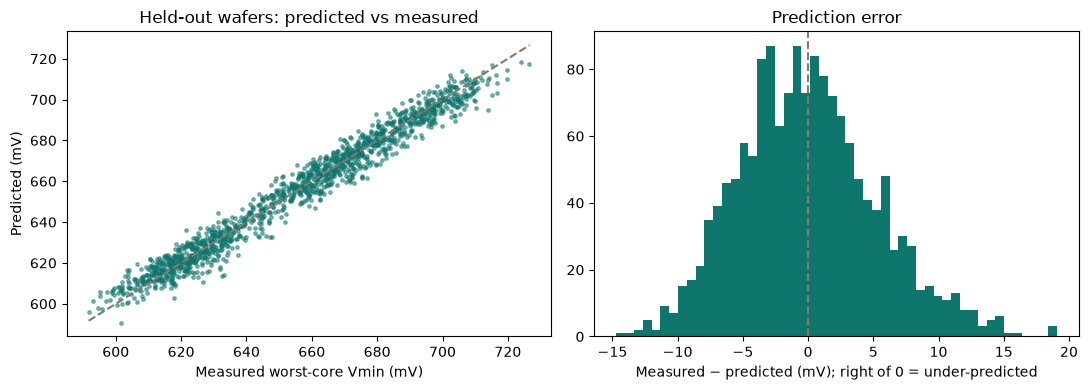

In [4]:
ridge = make_pipeline(StandardScaler(), Ridge(alpha=1.0)).fit(train[FEATURES], y_tr)
pred = ridge.predict(test[FEATURES])
err = y_te - pred
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(y_te, pred, s=6, color=TEAL, alpha=.5)
lo, hi = y_te.min(), y_te.max()
ax[0].plot([lo, hi], [lo, hi], color=GREY, ls="--")
ax[0].set(xlabel="Measured worst-core Vmin (mV)", ylabel="Predicted (mV)", title="Held-out wafers: predicted vs measured")
ax[1].hist(err, bins=50, color=TEAL)
ax[1].axvline(0, color=GREY, ls="--")
ax[1].set(xlabel="Measured − predicted (mV); right of 0 = under-predicted", title="Prediction error")
plt.tight_layout(); plt.show()

## 3 · Safety margin, chosen on validation wafers
Under-predicting Vmin is the dangerous direction: a chip would be given less voltage than it needs. So a margin is
added to the prediction. It is chosen on **validation wafers** (the smallest margin with **zero** under-estimates there,
the same rule as the 80 MHz speed margin), then checked **once** on the untouched test wafers.

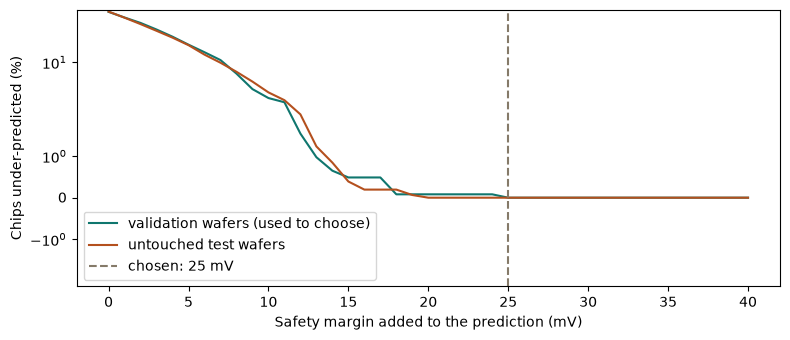

Chosen margin on validation: 25 mV


In [5]:
m_val = make_pipeline(StandardScaler(), Ridge(alpha=1.0)).fit(fit[FEATURES], fit.vmin_worst_mV)
e_val = val.vmin_worst_mV - m_val.predict(val[FEATURES])
grid = np.arange(0, 41)
curve = pd.DataFrame({"margin_mV": grid,
                      "validation_under_%": [(e_val > g).mean() * 100 for g in grid],
                      "test_under_%": [(err > g).mean() * 100 for g in grid]})
MARGIN = int(grid[(e_val.values[:, None] > grid).sum(axis=0) == 0][0])
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(curve.margin_mV, curve["validation_under_%"], color=TEAL, label="validation wafers (used to choose)")
ax.plot(curve.margin_mV, curve["test_under_%"], color=COPPER, label="untouched test wafers")
ax.axvline(MARGIN, color=GREY, ls="--", label=f"chosen: {MARGIN} mV")
ax.set(xlabel="Safety margin added to the prediction (mV)", ylabel="Chips under-predicted (%)", yscale="symlog")
ax.legend(); plt.tight_layout(); plt.show()
print("Chosen margin on validation:", MARGIN, "mV")

In [6]:
k, n = int((err > MARGIN).sum()), len(err)
upper95 = beta.ppf(0.95, k + 1, n - k)
print(f"Test wafers at {MARGIN} mV: {k} of {n} chips under-predicted ({k / n:.2%}); "
      f"95% upper bound {upper95:.2%}")
print(f"Average extra voltage given by the margin: {(MARGIN - err).clip(lower=0).mean():.1f} mV")
t0 = time.perf_counter(); ridge.predict(test[FEATURES]); per_chip_ms = (time.perf_counter() - t0) / n * 1000
print(f"Prediction time: {per_chip_ms:.4f} ms per chip (whole wafer at once)")

Test wafers at 25 mV: 0 of 1540 chips under-predicted (0.00%); 95% upper bound 0.19%
Average extra voltage given by the margin: 25.0 mV
Prediction time: 0.0014 ms per chip (whole wafer at once)


## 4 · Every wafer held out in turn
One split can be lucky, so each of the 20 wafers is held out in turn (trained on the other 19).

In [7]:
rows = []
for w in sorted(soc.wafer_id.unique()):
    tr_, te_ = soc[soc.wafer_id != w], soc[soc.wafer_id == w]
    p = make_pipeline(StandardScaler(), Ridge(alpha=1.0)).fit(tr_[FEATURES], tr_.vmin_worst_mV).predict(te_[FEATURES])
    e = te_.vmin_worst_mV - p
    rows.append({"wafer": w, "chips": len(te_), "MAE_mV": np.abs(e).mean(), "under_at_margin_%": (e > MARGIN).mean() * 100})
lowo = pd.DataFrame(rows)
print(f"MAE across wafers: median {lowo.MAE_mV.median():.2f} mV, range {lowo.MAE_mV.min():.2f}-{lowo.MAE_mV.max():.2f} mV")
print(f"Under-predicted at {MARGIN} mV, per wafer: max {lowo['under_at_margin_%'].max():.2f}%")
lowo.round(2)

MAE across wafers: median 4.19 mV, range 3.78-4.50 mV
Under-predicted at 25 mV, per wafer: max 0.00%


,wafer,chips,MAE_mV,under_at_margin_%
0,QA1-W01,308,4.12,0.0
1,QA1-W02,308,4.50,0.0
2,QA1-W03,308,3.78,0.0
3,QA1-W04,308,4.27,0.0
4,QA1-W05,308,4.12,0.0
5,QA2-W01,308,3.95,0.0
6,QA2-W02,308,4.50,0.0
7,QA2-W03,308,4.32,0.0
8,QA2-W04,308,4.08,0.0
9,QA2-W05,308,4.15,0.0


## 5 · Save the model
Saved as `vmin_models.joblib` next to the other model files; the website loads it as is.

In [8]:
ridge_row = results.set_index("model").loc["Ridge"]
bundle = {
    "model": ridge, "features": FEATURES, "target": "vmin_worst_mV", "margin_mV": MARGIN,
    "metrics": {"mae_mV": float(ridge_row["MAE (mV)"]), "r2": float(ridge_row["R2"]),
                "within10_pct": float(ridge_row["within ±10 mV"]),
                "baseline_mae_mV": float(results.set_index("model").loc["Median (baseline)", "MAE (mV)"]),
                "test_chips": int(n), "test_under_at_margin": k, "upper95_pct": float(upper95 * 100),
                "lowo_mae_median_mV": float(lowo.MAE_mV.median()), "lowo_mae_min_mV": float(lowo.MAE_mV.min()),
                "lowo_mae_max_mV": float(lowo.MAE_mV.max()), "per_chip_ms": float(per_chip_ms)},
    "test_wafers": sorted(test.wafer_id.unique()),
}
joblib.dump(bundle, "vmin_models.joblib", compress=3)
json.dumps(bundle["metrics"], indent=1)

'{\n "mae_mV": 4.19,\n "r2": 0.971,\n "within10_pct": 94.4,\n "baseline_mae_mV": 27.06,\n "test_chips": 1540,\n "test_under_at_margin": 0,\n "upper95_pct": 0.1943389864882908,\n "lowo_mae_median_mV": 4.194690193552847,\n "lowo_mae_min_mV": 3.78294418032867,\n "lowo_mae_max_mV": 4.501924878701142,\n "per_chip_ms": 0.0013522727433108277\n}'

## Conclusion
- **Ridge on the cheap monitors predicts worst-core Vmin with a typical error of about 4 mV** (R² about 0.97) on wafers
  it never saw, against about 27 mV for a single fleet-wide value.
- A **safety margin chosen on validation wafers** (zero under-estimates there) gave **zero under-predicted chips** on
  the untouched test wafers. Zero events in about 1,500 chips is not zero risk: the 95% upper bound is printed above.
- **What it is for:** a voltage estimate per chip before any voltage search, to flag chips with little voltage headroom
  and to shorten a Vmin search by starting near the answer.
- **Limits:** synthetic data; in this dataset the AVS bin is derived from speed, so this model does not replace the
  bin logic of notebook 04. A real flow would validate the margin on real wafers in shadow mode first.